# Proyecto 3: Mejorando algoritmos con CUDA
## Reconocimiento del alfabeto ASL con CNN2 + data augmentation: de secuencial a CUDA

**CC3069 Computación Paralela y Distribuida, Universidad del Valle de Guatemala, Semestre II 2026**

Este notebook es el **entregable de código**. Reúne en un solo lugar:

1. el **código secuencial original** del Laboratorio 3 (Keras/TensorFlow);
2. la **Fase 1: preparación de datos en CPU** (lectura de imágenes, preprocesamiento,
   `Dataset` y `DataLoader`);
3. la **Fase 2: configuración de CUDA y entrenamiento** (selección estricta del dispositivo,
   modelo, augmentation, forward/backward/Adam en la GPU);
4. un **kernel CUDA propio en CUDA Python (Numba)**, con el reparto en hilos, bloques y grid
   diseñado por nosotros;
5. los **resultados** del benchmark oficial: tiempos, speedup por fase y conclusiones.

| Hardware (misma laptop para CPU y CUDA) | |
|---|---|
| CPU | Intel Core i7-9750H, 6 núcleos / 12 hilos |
| GPU | NVIDIA GeForce GTX 1650, 4 GB, compute capability 7.5, driver 610.47 |
| RAM | 16 GB |
| Software | Python 3.11.9, PyTorch 2.6.0 (`+cpu` / `+cu126`), Numba 0.61.2 |

**Cómo ejecutarlo:** con el kernel de `.venv-cuda` (lo crea `scripts/setup_cuda.ps1`). Las
celdas de demostración corren en segundos. El benchmark oficial completo (10 épocas × 3
repeticiones por dispositivo) se ejecuta aparte con `scripts/run_full_benchmarks.ps1`, y aquí
solo se cargan sus resultados.

### Mapa del pipeline

```
               FASE 1: CPU (preparación de datos)                        FASE 2: GPU (entrenamiento)
 ┌────────────────────────────────────────────────────────┐        ┌──────────────────────────────────────────────┐
 │ JPG (Kaggle) → EXIF + RGB → resize 64×64 → .npy uint8  │        │ augmentation (rotación, traslación, zoom,    │
 │      (una sola vez, prepare_asl_data.py)                │        │   brillo, contraste)                         │
 │ .npy memmap → uint8→float32 [0,1], NHWC→NCHW → batch 32 │ ─────▶ │ forward CNN2 → CrossEntropy → backward → Adam│
 │      (cada época, ASLNpyDataset + DataLoader)          │ .to()  │ métricas por batch (argmax en GPU)           │
 └────────────────────────────────────────────────────────┘ pinned └──────────────────────────────────────────────┘
```

La frontera entre fases es una sola línea: `images.to(device, non_blocking=True)`. Todo lo
anterior es manejo de archivos y memoria en la CPU; todo lo posterior es álgebra de tensores
en la GPU.

In [1]:
import ast
import importlib.util
import inspect
import json
import sys
import time
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
from IPython.display import Image, Markdown, display

DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "reports" / "figures"
TAB_DIR = ROOT / "reports" / "tablas"
CHECKPOINT = ROOT / "results" / "initialization" / "cnn2_seed42_initial.pt"


def show_code(source: str, lang: str = "python") -> None:
    display(Markdown(f"```{lang}\n{source.rstrip()}\n```"))


def function_source(path: Path, *names: str) -> str:
    """Extrae funciones/clases de un archivo sin importarlo."""
    text = path.read_text(encoding="utf-8")
    tree = ast.parse(text)
    parts = [ast.get_source_segment(text, node) for node in tree.body
             if isinstance(node, (ast.FunctionDef, ast.ClassDef)) and node.name in names]
    return "\n\n\n".join(parts)


print("PyTorch", torch.__version__, "| CUDA disponible:", torch.cuda.is_available())

PyTorch 2.6.0+cu126 | CUDA disponible: True


---
# 1. Solución secuencial original (Laboratorio 3, Keras)

El Laboratorio 3 entrenó varios modelos. El mejor fue **CNN2_aug**: tres bloques
Conv-BN-Pool-Dropout, Global Average Pooling y una capa densa softmax de 29 clases, con data
augmentation como primera capa. Se entrenaba con `model.fit` de Keras, que ejecuta todo el
pipeline en un solo dispositivo y sin separar fases. Las celdas siguientes muestran el código
**tal como está** en `original_lab3/Notebooks/01_modelos_dl.ipynb`. Solo se muestra, no se
ejecuta, porque requiere TensorFlow.

In [2]:
orig_nb = json.loads((ROOT / "original_lab3" / "Notebooks" / "01_modelos_dl.ipynb").read_text(encoding="utf-8"))
orig_cells = ["".join(c["source"]) for c in orig_nb["cells"] if c["cell_type"] == "code"]


def original_cell(marker: str) -> str:
    return next(src for src in orig_cells if marker in src)


display(Markdown("**Augmentation original (capas Keras, se aplica dentro del modelo):**"))
aug_src = original_cell("data_augmentation = keras.Sequential")
show_code(aug_src.split("# Grilla")[0])

display(Markdown("**Arquitectura CNN2 original (versión sin augmentation; CNN2_aug antepone `data_augmentation`):**"))
show_code(original_cell('name="CNN2_regularizada"').split("cnn2.summary()")[0])

display(Markdown("**Entrenamiento original: un solo `model.fit` hace carga, augmentation, forward, backward y validación:**"))
show_code(original_cell("def entrenar_y_evaluar").split("    _, acc_val")[0])

**Augmentation original (capas Keras, se aplica dentro del modelo):**

```python
data_augmentation = keras.Sequential([
    layers.RandomRotation(0.04),                       # ~ ±15°
    layers.RandomTranslation(0.1, 0.1),                # ±10% vertical y horizontal
    layers.RandomZoom(0.1),                            # ±10%
    layers.RandomBrightness(0.2, value_range=(0, 1)),  # X ya está normalizado a [0,1]
    layers.RandomContrast(0.2),
], name="augmentation")
```

**Arquitectura CNN2 original (versión sin augmentation; CNN2_aug antepone `data_augmentation`):**

```python
cnn2 = keras.Sequential([
    layers.Conv2D(32, 3, activation="relu", padding="same", input_shape=X_train.shape[1:]),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),

    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),

    layers.Conv2D(128, 3, activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation="softmax"),
], name="CNN2_regularizada")
```

**Entrenamiento original: un solo `model.fit` hace carga, augmentation, forward, backward y validación:**

```python
def entrenar_y_evaluar(model, nombre, aug=False, epochs=30, batch_size=32):
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

    start = time.time()
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[early_stop],
        verbose=2,
    )
    tiempo_entreno_s = time.time() - start
```

In [3]:
orig_metrics = json.loads((ROOT / "original_lab3" / "Notebooks" / "results" / "metrics_CNN2_aug.json").read_text())
display(pd.DataFrame([orig_metrics]).set_index("modelo"))
display(Markdown(
    f"La ejecución histórica entrenó **18 épocas** (early stopping, mejor época 13) en "
    f"**{orig_metrics['tiempo_entreno_s']:.0f} s**, es decir, ≈ {orig_metrics['tiempo_entreno_s']/18:.0f} s por época, con "
    f"accuracy de test {orig_metrics['acc_test']:.3f}. Ese tiempo no separa carga, augmentation ni "
    "cómputo: es la razón principal de la refactorización."))

,aug,acc_val,acc_test,f1_macro,params,tiempo_entreno_s
modelo,,,,,,
CNN2_aug,True,0.831801,0.849042,0.848629,97885,664.6


La ejecución histórica entrenó **18 épocas** (early stopping, mejor época 13) en **665 s**, es decir, ≈ 37 s por época, con accuracy de test 0.849. Ese tiempo no separa carga, augmentation ni cómputo: es la razón principal de la refactorización.

### Qué se cambió y por qué

| Aspecto | Original (Keras) | Refactorizado (PyTorch + CUDA) |
|---|---|---|
| Datos | todo el split cargado en RAM como `float32` | `.npy` `uint8` con *memory map*; se convierte a `float32` un batch a la vez en CPU |
| Augmentation | capa dentro del modelo | módulo aparte (`CNN2Augmentation`) que corre **después** de mover el batch a la GPU |
| Dispositivo | implícito (TensorFlow decide) | **explícito y estricto**: `--device cpu` o `--device cuda`; si se pide CUDA y no hay GPU, se detiene sin pasar a CPU en silencio |
| Medición | un solo tiempo total | cada fase cronometrada con `torch.cuda.synchronize()` |
| Reproducibilidad | early stopping (número de épocas variable) | 10 épocas fijas, mismo checkpoint inicial (SHA-256) para CPU y CUDA |

La arquitectura, el optimizador (Adam `lr=1e-3`, `eps=1e-7`) y la política de augmentation
son los mismos. Las 97,885 cuentas de parámetros coinciden con Keras.

---
# 2. Fase 1: preparación de datos en CPU

Esta fase hace **manipulación de archivos y memoria**: abrir JPG, decodificarlos, corregir la
orientación EXIF, redimensionar, armar arreglos y batches. Son operaciones de E/S, con
ramificaciones y librerías de CPU (Pillow, NumPy). Hay poco cálculo por byte, así que
mandarlas a la GPU solo agregaría copias por PCIe.

## 2.1 Lectura y preprocesamiento de imágenes (una sola vez)

`original_lab3/src/prepare_asl_data.py` selecciona 20 bloques de 30 fotos por clase (14/3/3
para train/val/test, de modo que fotos consecutivas no se repartan entre conjuntos), y guarda
cada split como `.npy` `uint8` de 64×64×3.

In [4]:
PREP = ROOT / "original_lab3" / "src" / "prepare_asl_data.py"
show_code(function_source(PREP, "load_uint8", "materialize"))

```python
def load_uint8(path: Path) -> np.ndarray:
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image).convert("RGB")
        resized = image.resize(IMAGE_SIZE, Image.Resampling.BILINEAR)
        return np.asarray(resized, dtype=np.uint8)


def materialize(
    rows: dict[str, list[tuple[str, Path]]], output_dir: Path, class_names: list[str]
) -> None:
    output_dir.mkdir(parents=True, exist_ok=True)
    label_to_index = {label: index for index, label in enumerate(class_names)}

    for split_name, split_rows in rows.items():
        x = np.empty((len(split_rows), *IMAGE_SIZE, 3), dtype=np.uint8)
        y = np.empty(len(split_rows), dtype=np.int64)
        for index, (label, path) in enumerate(split_rows):
            x[index] = load_uint8(path)
            y[index] = label_to_index[label]
            if (index + 1) % 2000 == 0 or index + 1 == len(split_rows):
                print(f"{split_name}: {index + 1:,}/{len(split_rows):,} imagenes")
        np.save(output_dir / f"X_{split_name}.npy", x)
        np.save(output_dir / f"y_{split_name}.npy", y)
        print(f"Guardado {split_name}: X{x.shape}, y{y.shape}")

    (output_dir / "classes.json").write_text(
        json.dumps(class_names, indent=2), encoding="utf-8"
    )
    metadata = {
        "seed": SEED,
        "image_size": list(IMAGE_SIZE),
        "block_size": BLOCK_SIZE,
        "selected_blocks_per_class": BLOCKS_PER_CLASS,
        "split_blocks": SPLIT_BLOCKS,
        "images_per_class": {
            split_name: len(split_rows) // len(class_names)
            for split_name, split_rows in rows.items()
        },
        "total_images": {name: len(split_rows) for name, split_rows in rows.items()},
        "classes": class_names,
        "preprocessing": [
            "correccion de orientacion EXIF",
            "conversion explicita a RGB",
            "redimension bilineal a 64x64",
            "almacenamiento uint8; normalizacion posterior segun el modelo",
        ],
    }
    (output_dir / "preprocess_meta.json").write_text(
        json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8"
    )
```

In [5]:
sys.path.insert(0, str(ROOT / "original_lab3" / "src"))
import prepare_asl_data as prep  # importable por nombre: lo necesitan los procesos hijos

# Demostración en CPU con las fotos propias versionadas en el repo (no requiere el dataset de Kaggle).
sample_paths = sorted((ROOT / "original_lab3" / "asl_alphabet_test").rglob("*.jpg"))
start = time.perf_counter()
decoded = np.stack([prep.load_uint8(p) for p in sample_paths])
serial_s = time.perf_counter() - start
print(f"{len(sample_paths)} JPG decodificados y redimensionados en 1 núcleo: {serial_s:.2f} s "
      f"({1000 * serial_s / len(sample_paths):.0f} ms/imagen) → {decoded.shape} {decoded.dtype}")

meta = json.loads((DATA_DIR / "preprocess_meta.json").read_text(encoding="utf-8"))
display(pd.DataFrame(meta["total_images"], index=["imágenes"]))

100 JPG decodificados y redimensionados en 1 núcleo: 10.36 s (104 ms/imagen) → (100, 64, 64, 3) uint8


,train,val,test
imágenes,12180,2610,2610


## 2.2 `Dataset` y `DataLoader` (cada época, en CPU)

`ASLNpyDataset` abre los `.npy` con *memory map*: no los carga completos y lee solo la
imagen pedida. Cada `__getitem__` hace `uint8 → float32 / 255` y `NHWC → NCHW`. El
`DataLoader` arma batches de 32, baraja con semilla fija y, cuando el destino es CUDA, usa
**memoria *pinned*** para que la copia a la GPU sea por DMA y no bloqueante.

In [6]:
from src.data.asl_dataset import ASLNpyDataset, CNN2Augmentation
from src.train import make_loader

show_code(inspect.getsource(ASLNpyDataset.__getitem__))
show_code(inspect.getsource(make_loader))

```python
    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        image = np.array(self.images[index], dtype=np.uint8)  # copia de una imagen
        tensor = torch.from_numpy(image).permute(2, 0, 1).to(torch.float32).div_(255.0)
        label = torch.tensor(int(self.labels[index]), dtype=torch.int64)
        return tensor.contiguous(), label
```

```python
def make_loader(
    dataset: ASLNpyDataset,
    *,
    batch_size: int,
    shuffle: bool,
    num_workers: int,
    seed: int,
    device: torch.device,
) -> DataLoader:
    generator = torch.Generator(device="cpu").manual_seed(seed)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=num_workers,
        pin_memory=device.type == "cuda",
        persistent_workers=num_workers > 0,
        worker_init_fn=_worker_seed if num_workers > 0 else None,
        generator=generator,
    )
```

In [7]:
train_ds = ASLNpyDataset(DATA_DIR, "train")
loader = make_loader(train_ds, batch_size=32, shuffle=True, num_workers=0, seed=42,
                     device=torch.device("cuda" if torch.cuda.is_available() else "cpu"))
images, labels = next(iter(loader))
print("Batch producido por la Fase 1:")
print(f"  images  {tuple(images.shape)} {images.dtype}  rango [{images.min():.2f}, {images.max():.2f}]"
      f"  dispositivo={images.device}  pinned={images.is_pinned()}")
print(f"  labels  {tuple(labels.shape)} {labels.dtype}  dispositivo={labels.device}")
print(f"  {len(train_ds):,} imágenes de train → {len(loader)} batches por época")

Batch producido por la Fase 1:
  images  (32, 3, 64, 64) torch.float32  rango [0.00, 1.00]  dispositivo=cpu  pinned=True
  labels  (32,) torch.int64  dispositivo=cpu
  12,180 imágenes de train → 381 batches por época


## 2.3 Paralelismo en los núcleos de la CPU

### Decodificación de JPG: aquí está el trabajo pesado de CPU

Decodificar un JPG, corregir su orientación y redimensionarlo es trabajo independiente por
imagen y no necesita la GPU. Se reparte entre **procesos** de CPU con
`ProcessPoolExecutor`, uno por núcleo, lo que evita el GIL de Python.

In [8]:
from concurrent.futures import ProcessPoolExecutor

dec_rows = [{"procesos": 1, "tiempo_s": serial_s}]
for workers in (2, 4, 6):
    with ProcessPoolExecutor(max_workers=workers) as pool:
        list(pool.map(prep.load_uint8, sample_paths[:workers]))      # arranque de procesos, excluido
        t0 = time.perf_counter()
        parallel = list(pool.map(prep.load_uint8, sample_paths, chunksize=4))
        dec_rows.append({"procesos": workers, "tiempo_s": time.perf_counter() - t0})
assert np.array_equal(np.stack(parallel), decoded)               # mismo resultado que en serie
decod = pd.DataFrame(dec_rows).set_index("procesos")
decod["speedup"] = decod.loc[1, "tiempo_s"] / decod["tiempo_s"]
decod.round(2).to_csv(TAB_DIR / "decodificacion_jpg_multinucleo.csv", encoding="utf-8")
display(decod.round(2))
print(f"Extrapolado a las 17,400 imágenes del dataset: {17400 * serial_s / len(sample_paths) / 60:.0f} min en 1 núcleo "
      f"vs {17400 * decod['tiempo_s'].min() / len(sample_paths) / 60:.0f} min con {decod['tiempo_s'].idxmin()} procesos.")

,tiempo_s,speedup
procesos,,
1,10.36,1.00
2,5.76,1.80
4,3.61,2.87
6,3.29,3.15


Extrapolado a las 17,400 imágenes del dataset: 30 min en 1 núcleo vs 10 min con 6 procesos.


### Workers del `DataLoader`: aquí no conviene

PyTorch también permite repartir la preparación de batches entre procesos
(`num_workers > 0`). Se mide una época completa de solo carga, desde los `.npy` ya
preprocesados:

In [9]:
def time_loading(num_workers: int) -> tuple[float, float]:
    dl = make_loader(train_ds, batch_size=32, shuffle=True, num_workers=num_workers, seed=42,
                     device=torch.device("cpu"))
    t0 = time.perf_counter()
    it = iter(dl)
    next(it)                   # primer batch: incluye el arranque de los procesos worker
    t1 = time.perf_counter()
    for _ in it:
        pass
    t2 = time.perf_counter()
    del it, dl
    return t1 - t0, t2 - t1


rows = []
for w in (0, 2, 4):
    first, rest = time_loading(w)
    rows.append({"num_workers": w, "arranque_1er_batch_s": first, "resto_de_la_época_s": rest,
                 "época_completa_s": first + rest})
carga = pd.DataFrame(rows).set_index("num_workers")
carga["speedup_régimen"] = carga.loc[0, "resto_de_la_época_s"] / carga["resto_de_la_época_s"]
carga["speedup_con_arranque"] = carga.loc[0, "época_completa_s"] / carga["época_completa_s"]
carga.round(2).to_csv(TAB_DIR / "carga_num_workers.csv", encoding="utf-8")
display(carga.round(2))

,arranque_1er_batch_s,resto_de_la_época_s,época_completa_s,speedup_régimen,speedup_con_arranque
num_workers,,,,,
0,0.00,1.20,1.21,1.00,1.00
2,4.35,0.94,5.29,1.28,0.23
4,5.48,0.67,6.15,1.80,0.20


**Interpretación.** Los núcleos de la CPU sí aceleran la preparación de imágenes:

- **Decodificar JPG** cuesta ~100 ms por imagen y escala con los procesos (≈ 3× con 4-6).
  Es la parte pesada del manejo de archivos y se hace una sola vez, en CPU.
- **Cargar batches desde `.npy`** también se acelera con workers una vez que están en marcha
  (columna `speedup_régimen`). Pero en Windows cada worker es un proceso nuevo que importa
  PyTorch, y ese arranque cuesta más que lo que se ahorra en una sola época de 381 batches
  baratos (columna `speedup_con_arranque`). Con `persistent_workers=True` el arranque se
  paga una sola vez por entrenamiento.

El benchmark oficial usa `num_workers=0` para que CPU y CUDA midan exactamente el mismo
pipeline de carga. La carga ocupa ~17 s de ~96 s en CUDA (18 %), así que repartirla entre
núcleos es la siguiente optimización natural, y no necesita la GPU.

---
# 3. Fase 2: configuración de CUDA y entrenamiento en la GPU

## 3.1 Selección estricta del dispositivo

Si se pide `cuda` y PyTorch no ve una GPU, el programa se detiene con un error en vez de
entrenar en CPU sin avisar, lo que invalidaría la comparación.

In [10]:
from src.utils.device import select_device

show_code(inspect.getsource(select_device))
device = select_device("cuda")
props = torch.cuda.get_device_properties(device)
print(f"Dispositivo: {torch.cuda.get_device_name(device)} | {props.total_memory / 2**30:.1f} GiB | "
      f"{props.multi_processor_count} SM | compute capability {props.major}.{props.minor}")
print(f"CUDA (PyTorch) {torch.version.cuda} | cuDNN {torch.backends.cudnn.version()} | "
      f"cudnn.enabled={torch.backends.cudnn.enabled}")

```python
def select_device(requested: str = "auto") -> torch.device:
    normalized = requested.strip().lower()
    if normalized == "cpu":
        return torch.device("cpu")
    if normalized == "cuda":
        if not torch.cuda.is_available():
            raise RuntimeError(
                "Se solicitó CUDA, pero torch.cuda.is_available() es False. "
                "Instale la rueda CUDA en una computadora NVIDIA con driver compatible; "
                "no se usará CPU silenciosamente."
            )
        return torch.device("cuda")
    if normalized == "auto":
        return torch.device("cuda" if torch.cuda.is_available() else "cpu")
    raise ValueError("device debe ser 'auto', 'cpu' o 'cuda'")
```

Dispositivo: NVIDIA GeForce GTX 1650 | 4.0 GiB | 16 SM | compute capability 7.5
CUDA (PyTorch) 12.6 | cuDNN 90501 | cudnn.enabled=True


## 3.2 Modelo, augmentation y optimizador en la GPU

`CNN2` es la traducción NCHW de la arquitectura Keras. El augmentation es un `nn.Module`
aparte que usa `affine_grid` / `grid_sample` (kernels CUDA de PyTorch) para las tres
transformaciones geométricas, más operaciones elemento a elemento para el brillo y el
contraste. Los tres objetos viven en el mismo dispositivo.

In [11]:
from src.models.cnn2 import CNN2, create_cnn2, load_initial_checkpoint, make_adam

show_code(inspect.getsource(CNN2.forward))
show_code(inspect.getsource(CNN2Augmentation.forward))

```python
    def forward(self, inputs: torch.Tensor) -> torch.Tensor:
        x = self.dropout1(self.pool1(self.bn1(torch.relu(self.conv1(inputs)))))
        x = self.dropout2(self.pool2(self.bn2(torch.relu(self.conv2(x)))))
        x = self.dropout3(self.pool3(self.bn3(torch.relu(self.conv3(x)))))
        x = self.global_average_pool(x)
        x = torch.flatten(x, start_dim=1)
        x = self.dropout4(x)
        return self.classifier(x)
```

```python
    def forward(self, images: torch.Tensor) -> torch.Tensor:
        if not self.training:
            return images
        batch = images.shape[0]
        zeros = images.new_zeros(batch)
        ones = images.new_ones(batch)

        # 1. Rotación alrededor del centro.
        angle = self._uniform(images, -self.rotation, self.rotation).squeeze(1) * (2.0 * math.pi)
        cos, sin = torch.cos(angle), torch.sin(angle)
        theta = torch.stack(
            (torch.stack((cos, -sin, zeros), dim=1), torch.stack((sin, cos, zeros), dim=1)),
            dim=1,
        )
        images = self._warp(images, theta)

        # 2. Traslación: una fracción f del lado equivale a 2f en coordenadas [-1,1].
        shift = self._uniform(images, -self.translation, self.translation, columns=2) * 2.0
        theta = torch.stack(
            (
                torch.stack((ones, zeros, shift[:, 0]), dim=1),
                torch.stack((zeros, ones, shift[:, 1]), dim=1),
            ),
            dim=1,
        )
        images = self._warp(images, theta)

        # 3. Zoom isotrópico (mismo factor en alto y ancho).
        scale = 1.0 + self._uniform(images, -self.zoom, self.zoom).squeeze(1)
        theta = torch.stack(
            (torch.stack((scale, zeros, zeros), dim=1), torch.stack((zeros, scale, zeros), dim=1)),
            dim=1,
        )
        images = self._warp(images, theta)

        # 4. Brillo sobre el rango [0,1].
        delta = self._uniform(images, -self.brightness, self.brightness).view(batch, 1, 1, 1)
        images = (images + delta).clamp(0.0, 1.0)

        # 5. Contraste alrededor de la media espacial de cada canal.
        factor = self._uniform(images, 1.0 - self.contrast, 1.0 + self.contrast).view(
            batch, 1, 1, 1
        )
        mean = images.mean(dim=(2, 3), keepdim=True)
        return ((images - mean) * factor + mean).clamp(0.0, 1.0)
```

In [12]:
model = create_cnn2(seed=42).to(device)
load_initial_checkpoint(model, CHECKPOINT, map_location=device)
augmentation = CNN2Augmentation().to(device).train()
optimizer = make_adam(model)
criterion = torch.nn.CrossEntropyLoss()
print("Parámetros del modelo en:", next(model.parameters()).device)
print("Estado de Adam: lr", optimizer.defaults["lr"], "| eps", optimizer.defaults["eps"])

Parámetros del modelo en: cuda:0
Estado de Adam: lr 0.001 | eps 1e-07


## 3.3 Un paso de entrenamiento, con el dispositivo de cada tensor

Se sigue un batch real a través de la frontera CPU → GPU:

In [13]:
trace = []
cpu_images, cpu_labels = next(iter(loader))                       # Fase 1 (CPU)
trace.append(("batch del DataLoader", cpu_images.device, cpu_images.is_pinned()))

gpu_images = cpu_images.to(device, non_blocking=True)            # frontera: copia host→device
gpu_labels = cpu_labels.to(device, non_blocking=True)
trace.append(("después de .to(device)", gpu_images.device, None))

model.train()
aug_images = augmentation(gpu_images)                             # Fase 2 (GPU)
trace.append(("después del augmentation", aug_images.device, None))
optimizer.zero_grad(set_to_none=True)
logits = model(aug_images)
trace.append(("logits (forward)", logits.device, None))
loss = criterion(logits, gpu_labels)
loss.backward()
trace.append(("gradiente conv1 (backward)", model.conv1.weight.grad.device, None))
optimizer.step()
torch.cuda.synchronize()
display(pd.DataFrame(trace, columns=["etapa", "dispositivo", "pinned"]).set_index("etapa"))
print(f"loss del batch: {loss.item():.4f}")

,dispositivo,pinned
etapa,,
batch del DataLoader,cpu,True
después de .to(device),cuda:0,None
después del augmentation,cuda:0,None
logits (forward),cuda:0,None
gradiente conv1 (backward),cuda:0,None


loss del batch: 4.6493


## 3.4 Bucle de entrenamiento instrumentado

`train_one_epoch` (en `src/train.py`) cronometra cada fase por separado. En CUDA, cada
medición termina con `torch.cuda.synchronize()`: los kernels se lanzan de forma asíncrona y,
sin la sincronización, su tiempo se atribuiría a la fase siguiente.

In [14]:
from src.train import _timed, train_one_epoch

show_code(inspect.getsource(_timed))
src_epoch = inspect.getsource(train_one_epoch)
show_code(src_epoch[src_epoch.index("    while max_batches"):src_epoch.index("        def update_metrics")])

```python
def _timed(device: torch.device, operation: Callable[[], T]) -> tuple[T, float]:
    _synchronize(device)
    start = time.perf_counter()
    result = operation()
    _synchronize(device)
    return result, time.perf_counter() - start
```

```python
    while max_batches is None or batches < max_batches:
        load_start = time.perf_counter()
        try:
            cpu_images, cpu_labels = next(iterator)
        except StopIteration:
            break
        timings["load_cpu_s"] += time.perf_counter() - load_start

        (images, labels), elapsed = _timed(
            device,
            lambda: (
                cpu_images.to(device, non_blocking=device.type == "cuda"),
                cpu_labels.to(device, non_blocking=device.type == "cuda"),
            ),
        )
        timings["transfer_s"] += elapsed

        images, elapsed = _timed(device, lambda: augmentation(images))
        timings["augmentation_s"] += elapsed

        _, elapsed = _timed(device, lambda: optimizer.zero_grad(set_to_none=True))
        timings["zero_grad_s"] += elapsed
        logits, elapsed = _timed(device, lambda: model(images))
        timings["forward_s"] += elapsed
        loss, elapsed = _timed(device, lambda: criterion(logits, labels))
        timings["loss_s"] += elapsed
        _, elapsed = _timed(device, loss.backward)
        timings["backward_s"] += elapsed
        _, elapsed = _timed(device, optimizer.step)
        timings["optimizer_s"] += elapsed
```

### Demostración: los mismos 60 batches en CPU y en CUDA

Es una muestra corta para ver la separación de fases en vivo. **No sustituye** al benchmark
oficial, que corre 10 épocas × 3 repeticiones (sección 5).

In [15]:
def demo(device_name: str, batches: int = 60) -> dict[str, float]:
    dev = torch.device(device_name)
    m = create_cnn2(seed=42).to(dev)
    load_initial_checkpoint(m, CHECKPOINT, map_location=dev)
    aug = CNN2Augmentation().to(dev)
    opt = make_adam(m)
    dl = make_loader(train_ds, batch_size=32, shuffle=True, num_workers=0, seed=42, device=dev)
    train_one_epoch(m, aug, dl, opt, criterion, dev, max_batches=5)          # warm-up
    torch.manual_seed(42)
    result = train_one_epoch(m, aug, dl, opt, criterion, dev, max_batches=batches)
    return result["timings"]


demo_rows = {"CPU": demo("cpu"), "CUDA": demo("cuda")}
cols = ["load_cpu_s", "transfer_s", "augmentation_s", "forward_s", "backward_s",
        "optimizer_s", "epoch_wall_s"]
demo_df = pd.DataFrame(demo_rows).loc[cols]
demo_df["speedup"] = demo_df["CPU"] / demo_df["CUDA"]
display(demo_df.round(3))

,CPU,CUDA,speedup
load_cpu_s,0.312,0.252,1.237
transfer_s,0.001,0.015,0.048
augmentation_s,0.306,0.226,1.354
forward_s,2.611,0.258,10.134
backward_s,2.604,0.460,5.664
optimizer_s,0.135,0.069,1.959
epoch_wall_s,5.998,1.353,4.434


### Ejecución oficial

El benchmark completo se lanzó una vez por dispositivo, con los mismos datos, semilla y
checkpoint:

```powershell
.\scripts\run_full_benchmarks.ps1 -ConfirmFullBenchmark
#   .venv-cpu  : python -m src.benchmark --device cpu  --epochs 10 --batch-size 32 --repetitions 3 --num-workers 0 --seed 42
#   .venv-cuda : python -m src.benchmark --device cuda --epochs 10 --batch-size 32 --repetitions 3 --num-workers 0 --seed 42
```

Los resultados están en `results/benchmarks/{cpu,cuda}/` (`benchmark.json`, `epochs.csv`,
`runs.csv`, `benchmark.log`) y se analizan en `notebooks/04_analisis_resultados.ipynb`.

---
# 4. Kernel CUDA propio en CUDA Python (Numba)

En la Fase 2 el reparto de hilos lo deciden PyTorch y cuDNN. Para **diseñar e implementar
nosotros** la distribución en hilos, bloques y grid, el brillo y el contraste del
augmentation se reescribieron como dos kernels con `@cuda.jit`
(`src/cuda_kernels/photometric.py`). El desarrollo completo, con la verificación y el
benchmark, está en `notebooks/05_kernel_numba_cuda.ipynb`, que corre en `.venv-numba`.

| Kernel | Grid | Bloque | Trabajo de cada hilo |
|---|---|---|---|
| `brightness_mean_kernel` | `N·C` bloques (96 en un batch de 32) | 256 hilos | brillo sobre 16 píxeles con paso 256 (accesos *coalesced*) + suma parcial; reducción en árbol en memoria compartida (8 pasos con `syncthreads`) → media del canal |
| `contrast_kernel` | `(W/16, H/16, N·C)` = (4, 4, 96) | 16×16 = 256 hilos | contraste de **1 píxel**: 393,216 hilos por batch |

Son dos kernels porque el contraste necesita la media completa de cada canal, y CUDA no puede
sincronizar bloques distintos dentro de un mismo kernel.

In [16]:
KERNEL_SRC = ROOT / "src" / "cuda_kernels" / "photometric.py"
text = KERNEL_SRC.read_text(encoding="utf-8")
start = text.index("@cuda.jit\ndef brightness_mean_kernel")
end = text.index("def photometric_cuda")
show_code(text[start:end])

```python
@cuda.jit
def brightness_mean_kernel(images, delta, out, means):
    """Un bloque por (imagen, canal). images/out: (N, C, H, W) float32."""
    plane = cuda.blockIdx.x  # índice lineal del par (imagen, canal)
    channels = images.shape[1]
    n = plane // channels
    c = plane % channels
    height = images.shape[2]
    width = images.shape[3]
    pixels = height * width

    tid = cuda.threadIdx.x
    partial = cuda.shared.array(THREADS_PER_BLOCK_REDUCE, dtype=np.float32)

    acc = np.float32(0.0)
    d = delta[n]
    i = tid
    while i < pixels:  # bucle con paso blockDim: hilos vecinos → píxeles vecinos
        y = i // width
        x = i % width
        v = images[n, c, y, x] + d
        v = min(max(v, np.float32(0.0)), np.float32(1.0))
        out[n, c, y, x] = v
        acc += v
        i += cuda.blockDim.x
    partial[tid] = acc
    cuda.syncthreads()

    stride = cuda.blockDim.x // 2  # reducción en árbol en memoria compartida
    while stride > 0:
        if tid < stride:
            partial[tid] += partial[tid + stride]
        cuda.syncthreads()
        stride //= 2

    if tid == 0:
        means[n, c] = partial[0] / pixels


@cuda.jit
def contrast_kernel(out, factor, means):
    """Un hilo por píxel. grid = (W/16, H/16, N*C), block = (16, 16)."""
    x = cuda.blockIdx.x * cuda.blockDim.x + cuda.threadIdx.x
    y = cuda.blockIdx.y * cuda.blockDim.y + cuda.threadIdx.y
    plane = cuda.blockIdx.z
    channels = out.shape[1]
    n = plane // channels
    c = plane % channels
    if y < out.shape[2] and x < out.shape[3]:  # guarda por si H o W no son múltiplos de 16
        m = means[n, c]
        v = (out[n, c, y, x] - m) * factor[n] + m
        out[n, c, y, x] = min(max(v, np.float32(0.0)), np.float32(1.0))


def launch_config(shape: tuple[int, int, int, int]) -> dict[str, tuple[int, ...]]:
    """Configuración de lanzamiento para un batch (N, C, H, W)."""
    n, c, h, w = shape
    return {
        "reduce_grid": (n * c,),
        "reduce_block": (THREADS_PER_BLOCK_REDUCE,),
        "contrast_grid": (math.ceil(w / TILE), math.ceil(h / TILE), n * c),
        "contrast_block": (TILE, TILE),
    }


def photometric_gpu(d_images, d_delta, d_factor, d_out, d_means) -> None:
    """Lanza los dos kernels sobre arreglos que ya están en la GPU (sin copiar)."""
    cfg = launch_config(d_images.shape)
    brightness_mean_kernel[cfg["reduce_grid"], cfg["reduce_block"]](
        d_images, d_delta, d_out, d_means
    )
    contrast_kernel[cfg["contrast_grid"], cfg["contrast_block"]](d_out, d_factor, d_means)
```

**Tiempo por época de brillo + contraste (12,180 imágenes, media de 5 repeticiones, s)**

,CPU NumPy,CPU secuencial (1 hilo),CPU paralelo (12 hilos),CUDA con copias CPU↔GPU,"CUDA, datos en GPU"
batch,,,,,
32,2.2615,0.5632,0.5491,1.5502,0.2912
128,1.8209,0.4259,0.4156,0.6303,0.0639
512,1.7750,0.4622,0.2102,0.5299,0.0276
2048,1.4964,0.4093,0.1787,0.3947,0.0271


**Speedup respecto a la CPU secuencial (1 hilo)**

,CPU NumPy,CPU secuencial (1 hilo),CPU paralelo (12 hilos),CUDA con copias CPU↔GPU,"CUDA, datos en GPU"
batch,,,,,
32,0.25,1.0,1.03,0.36,1.93
128,0.23,1.0,1.02,0.68,6.67
512,0.26,1.0,2.20,0.87,16.72
2048,0.27,1.0,2.29,1.04,15.09


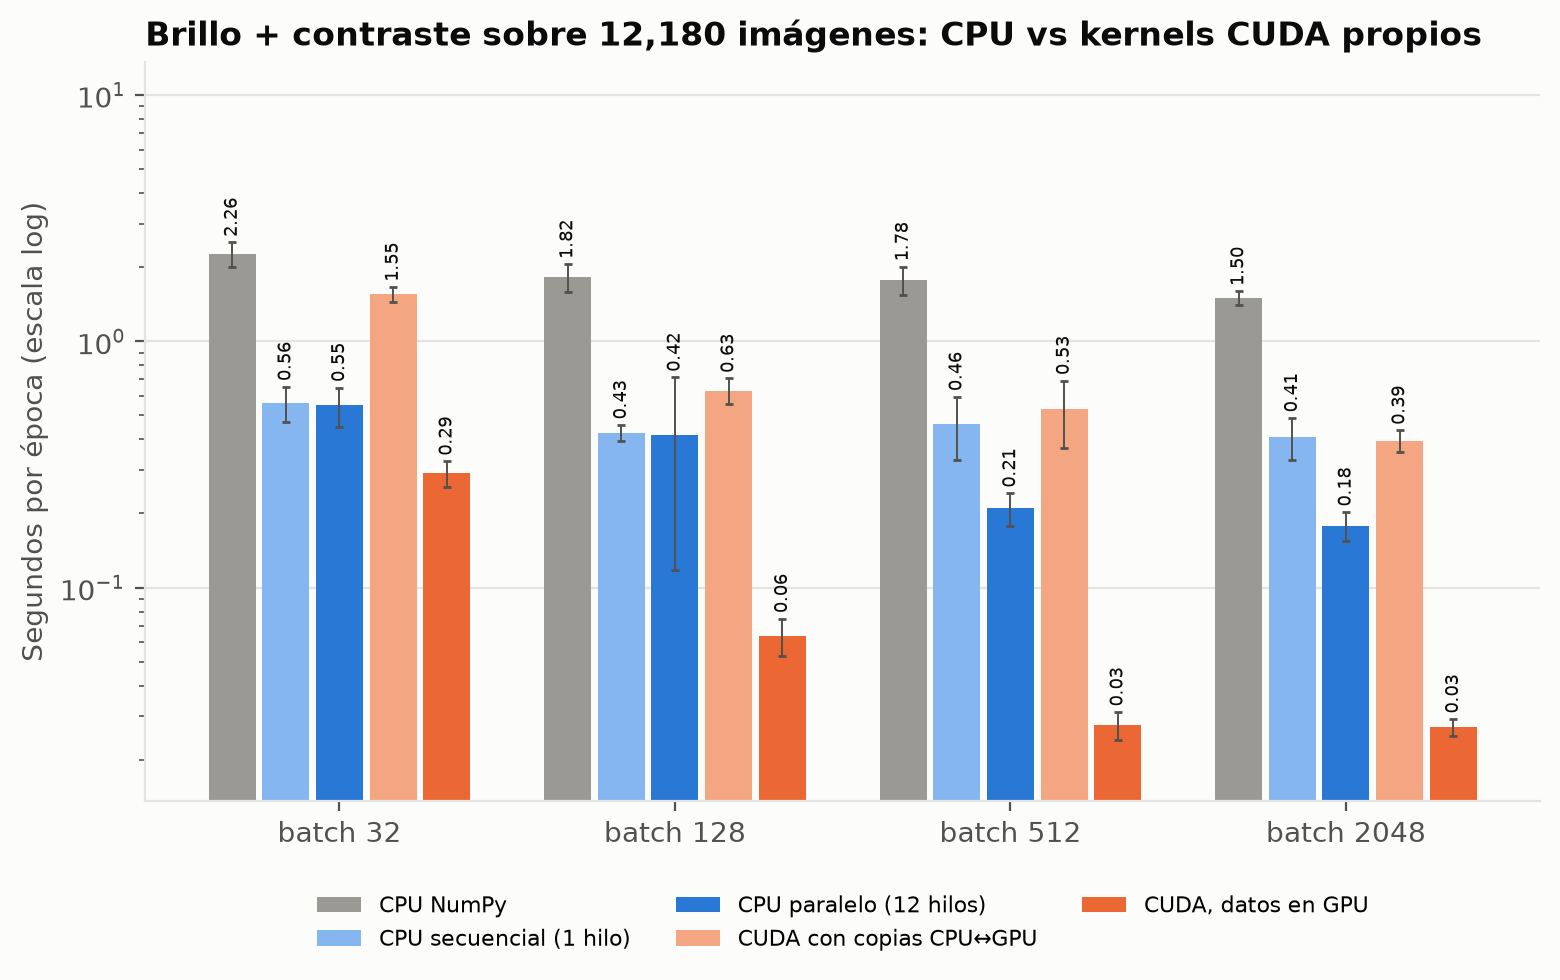

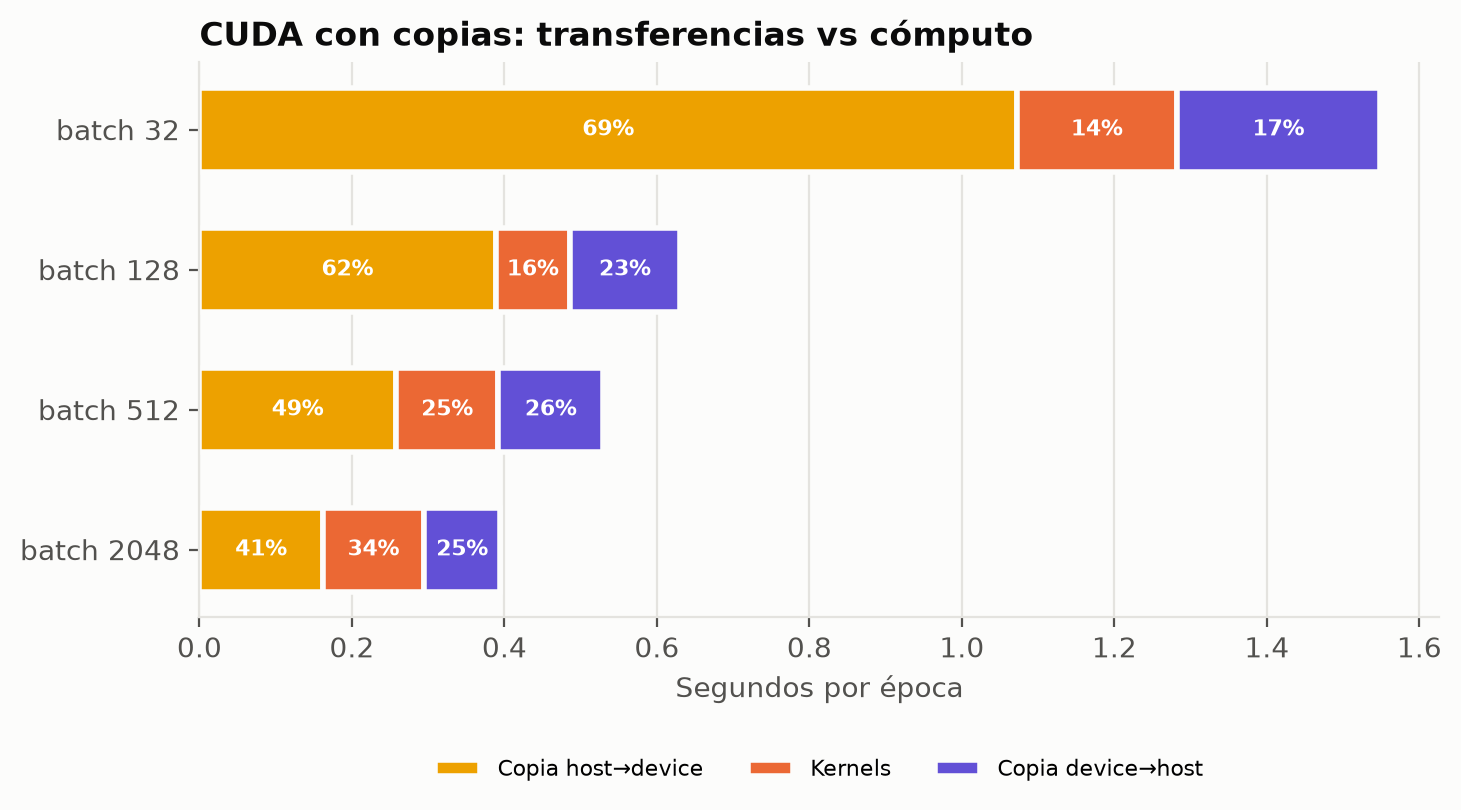

In [17]:
k_t = pd.read_csv(TAB_DIR / "kernel_tiempos.csv", index_col=0)
k_s = pd.read_csv(TAB_DIR / "kernel_speedup_vs_secuencial.csv", index_col=0)
display(Markdown("**Tiempo por época de brillo + contraste (12,180 imágenes, media de 5 repeticiones, s)**"))
display(k_t)
display(Markdown("**Speedup respecto a la CPU secuencial (1 hilo)**"))
display(k_s)
display(Image(filename=str(FIG_DIR / "08_kernel_tiempos.png"), width=820))
display(Image(filename=str(FIG_DIR / "09_kernel_desglose_copias.png"), width=700))

Con los datos ya en la GPU (como en el pipeline real, donde el augmentation corre después
de la copia), el kernel propio supera a la CPU secuencial por un orden de magnitud. Si en
cambio cada batch se copia a la GPU y de vuelta, las transferencias PCIe ocupan la mayor
parte del tiempo y la ventaja desaparece. Por eso el diseño de la Fase 2 copia el batch
**una sola vez** y mantiene todo lo demás en la GPU.

---
# 5. Resultados del benchmark oficial

10 épocas, batch 32, 3 repeticiones, seed 42, `num_workers=0`, mismo checkpoint inicial.
Las tablas y figuras las genera `notebooks/04_analisis_resultados.ipynb` a partir de
`results/benchmarks/`.

In [18]:
rep = pd.read_csv(TAB_DIR / "tiempos_por_repeticion.csv", index_col=0)
display(Markdown("**Tiempo medido por repetición (s)**"))
display(rep)
fases = pd.read_csv(TAB_DIR / "tiempos_y_speedup_por_fase.csv", index_col=0)
display(Markdown("**Tiempo y speedup por fase (suma de 10 épocas, media de 3 repeticiones)**"))
display(fases[["CPU media (s)", "CUDA media (s)", "Speedup (CPU/CUDA)",
               "% del total CPU", "% del total CUDA"]].round(2))

**Tiempo medido por repetición (s)**

,CPU (i7-9750H),CUDA (GTX 1650)
repetition,,
1,402.84,95.34
2,408.54,96.65
3,405.49,97.00
Media,405.62,96.33
Desv. estándar,2.85,0.87


**Tiempo y speedup por fase (suma de 10 épocas, media de 3 repeticiones)**

,CPU media (s),CUDA media (s),Speedup (CPU/CUDA),% del total CPU,% del total CUDA
Carga de datos (CPU),17.39,17.94,0.97,4.29,18.62
Transferencia host→device,0.05,0.96,0.05,0.01,0.99
Data augmentation,17.29,15.95,1.08,4.26,16.56
zero_grad,0.60,0.76,0.79,0.15,0.79
Forward,163.08,15.66,10.42,40.21,16.26
Loss,0.28,0.80,0.36,0.07,0.83
Backward,166.12,28.80,5.77,40.95,29.90
Optimizador (Adam),6.76,4.05,1.67,1.67,4.21
Métricas,0.35,1.70,0.20,0.09,1.77
Overhead no atribuido,0.33,1.21,0.27,0.08,1.26


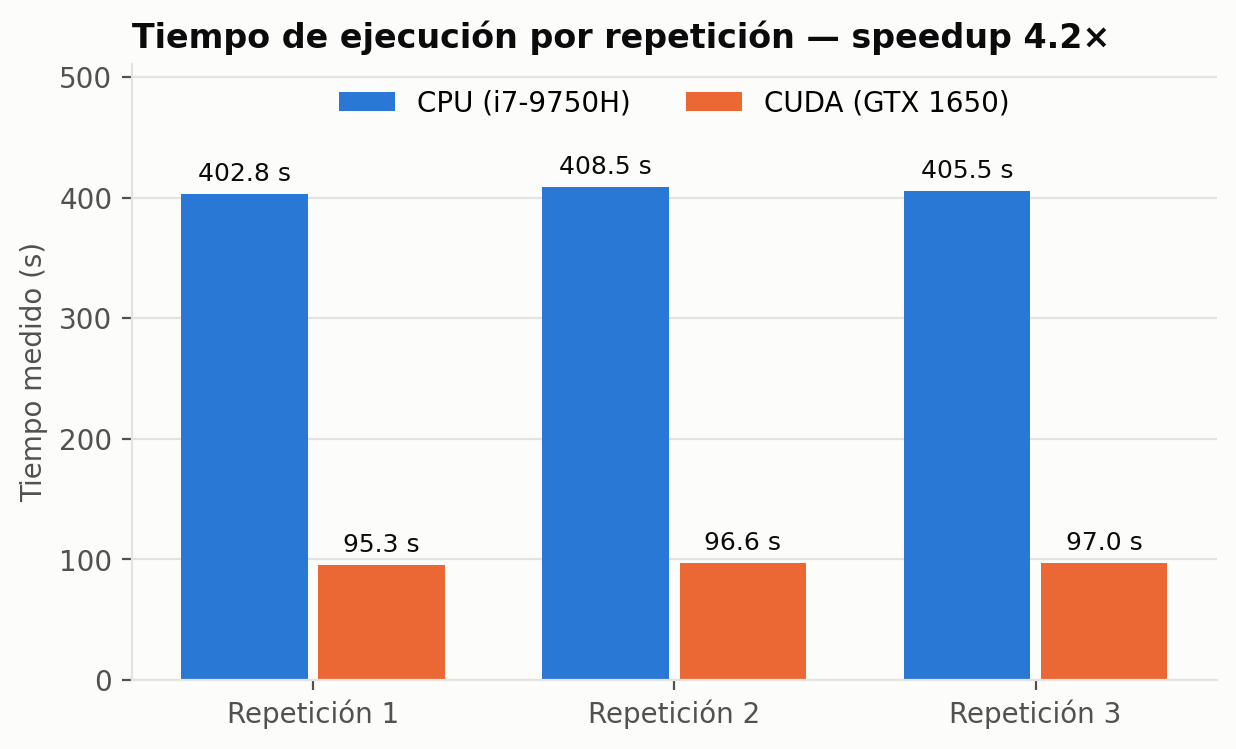

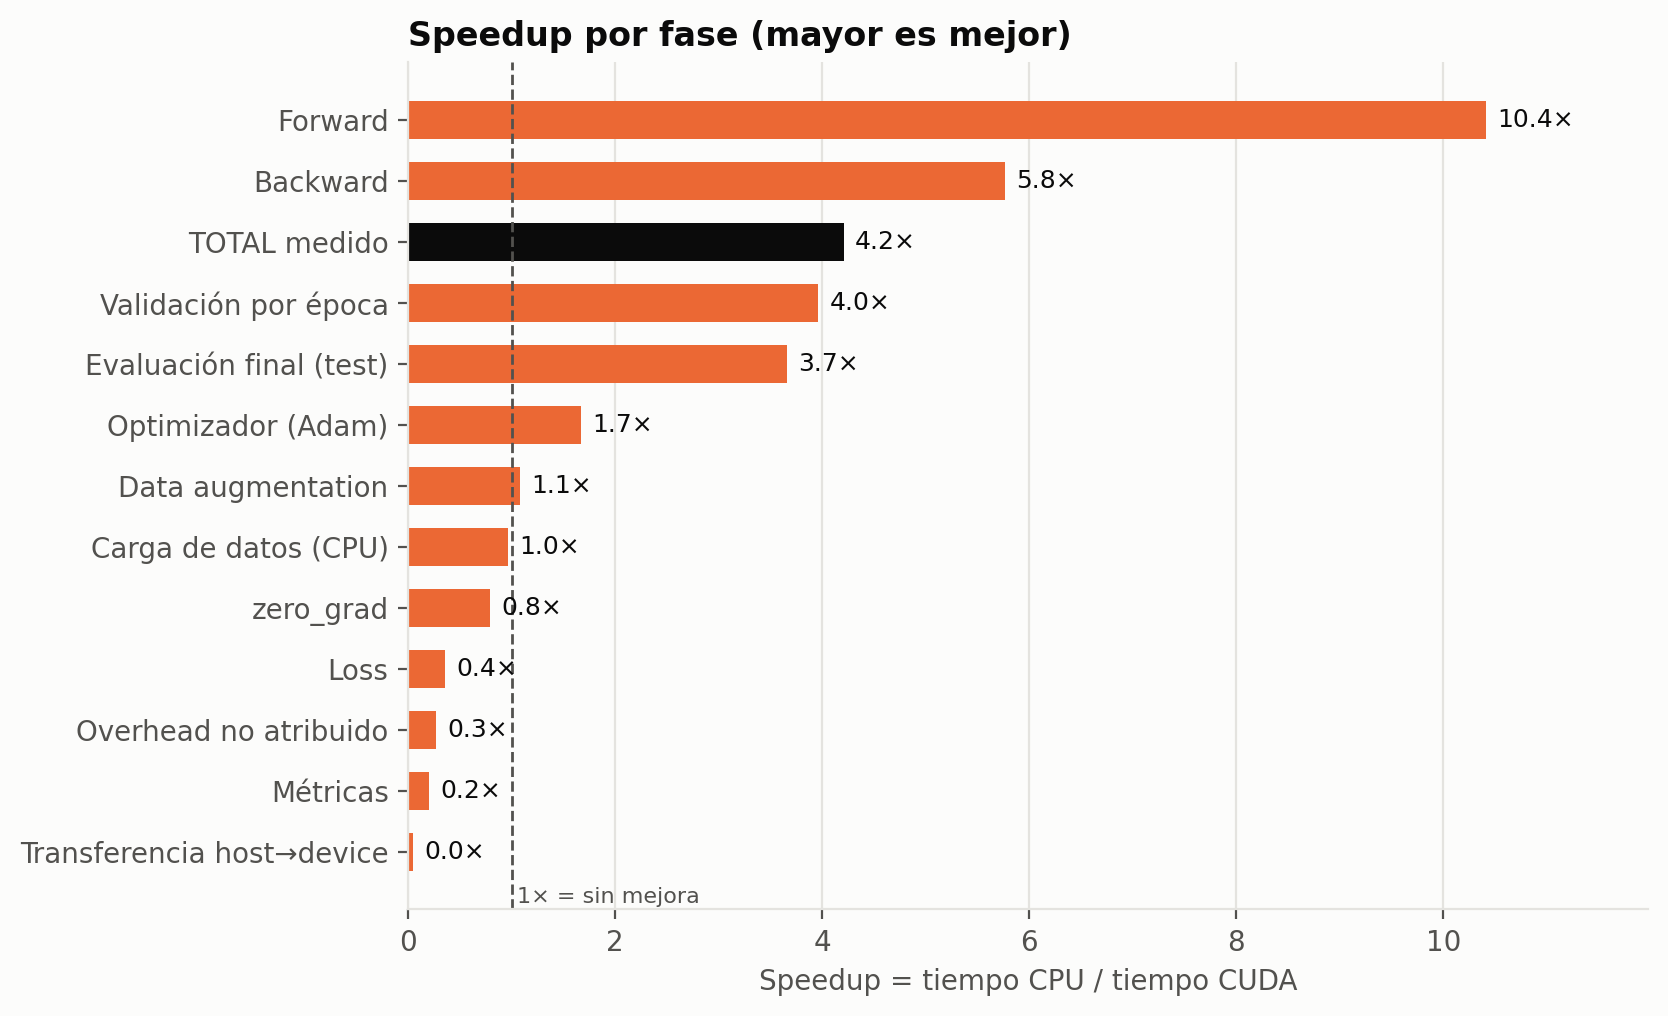

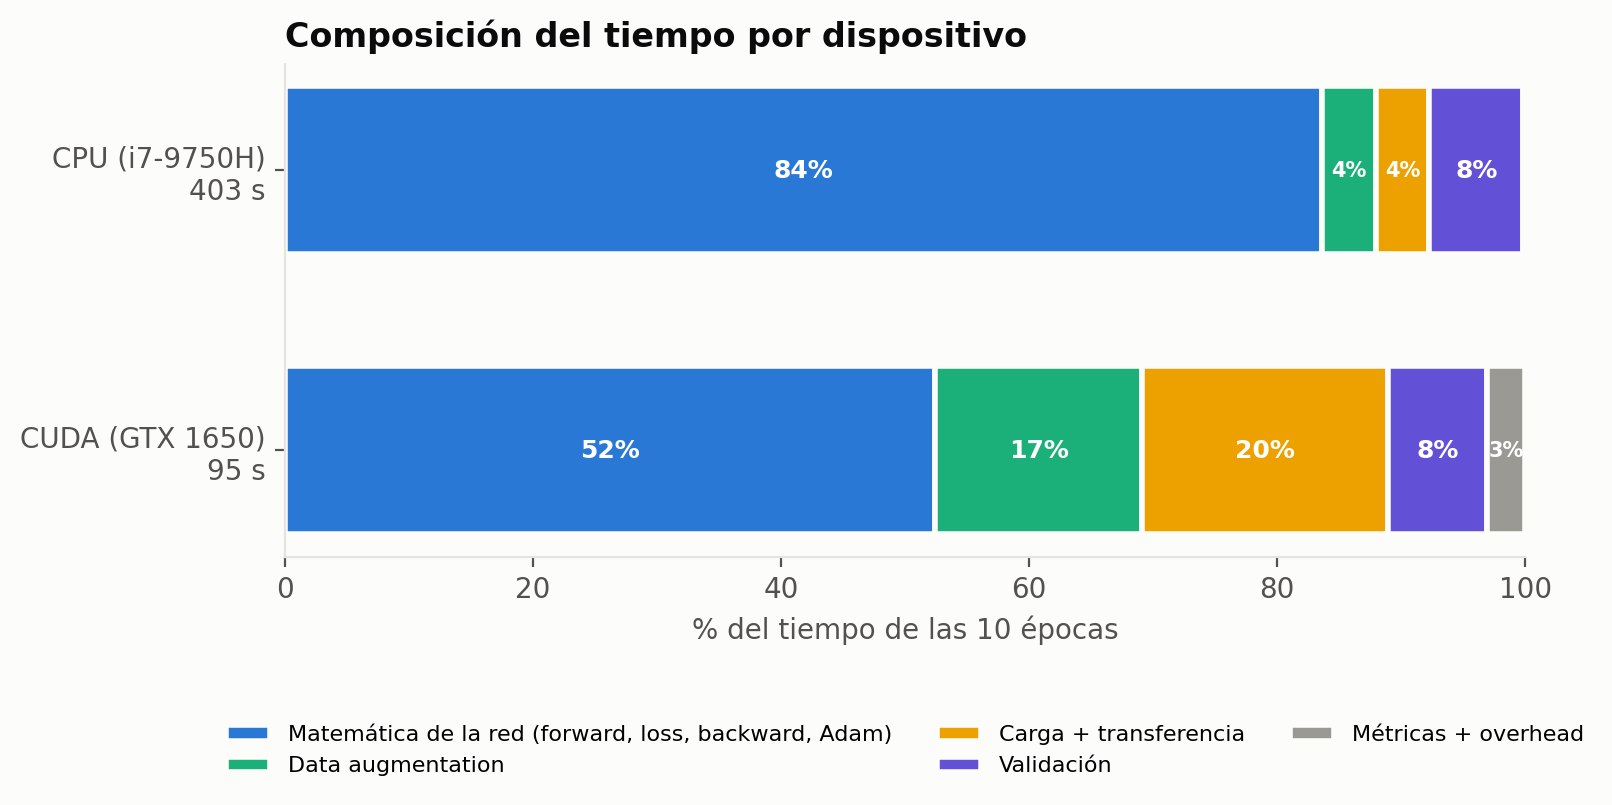

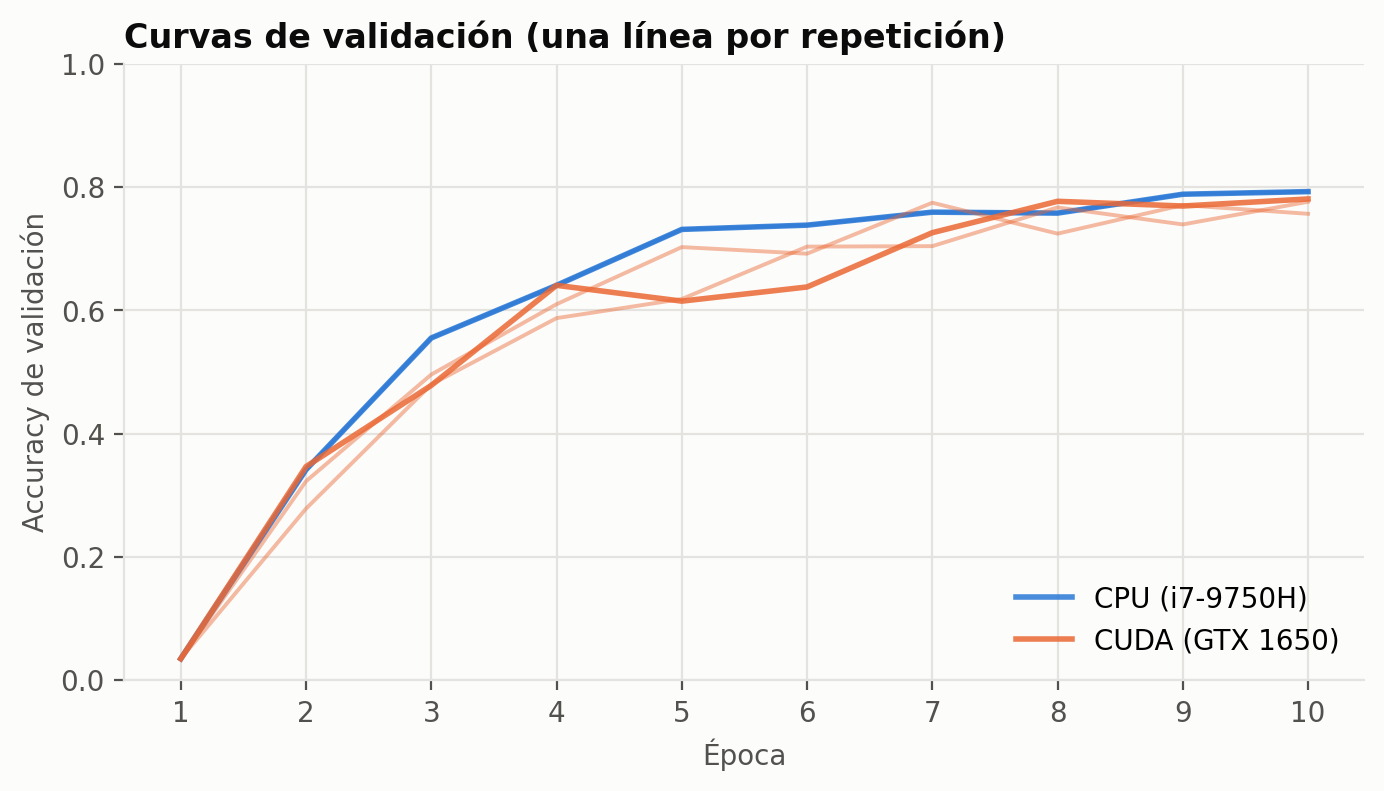

In [19]:
for name, width in [("01_tiempo_por_repeticion.png", 640), ("03_speedup_por_fase.png", 700),
                    ("04_composicion_por_dispositivo.png", 720), ("06_curvas_validacion.png", 640)]:
    display(Image(filename=str(FIG_DIR / name), width=width))

In [20]:
calidad = pd.read_csv(TAB_DIR / "calidad_test.csv", header=[0, 1], index_col=0)
display(Markdown("**Calidad en test (2,610 imágenes)**"))
display(calidad)

total = fases.loc["TOTAL medido"]
display(Markdown(
    f"**Speedup total: {total['Speedup (CPU/CUDA)']:.2f}×** "
    f"({total['CPU media (s)']:.1f} s en CPU → {total['CUDA media (s)']:.1f} s en CUDA). "
    f"Forward {fases.loc['Forward', 'Speedup (CPU/CUDA)']:.1f}×, backward "
    f"{fases.loc['Backward', 'Speedup (CPU/CUDA)']:.1f}×, validación "
    f"{fases.loc['Validación por época', 'Speedup (CPU/CUDA)']:.1f}×; la carga de datos (CPU en ambos) "
    f"queda en {fases.loc['Carga de datos (CPU)', 'Speedup (CPU/CUDA)']:.2f}×."))

**Calidad en test (2,610 imágenes)**

test_accuracy                         test_f1_macro                  \
                mean     std     min     max          mean     std     min   
device                                                                       
cpu           0.8211  0.0000  0.8211  0.8211        0.8233  0.0000  0.8233   
cuda          0.7554  0.0401  0.7184  0.7981        0.7484  0.0455  0.7056   

                
           max  
device          
cpu     0.8233  
cuda    0.7963

**Speedup total: 4.21×** (405.6 s en CPU → 96.3 s en CUDA). Forward 10.4×, backward 5.8×, validación 4.0×; la carga de datos (CPU en ambos) queda en 0.97×.

---
# 6. Conclusiones

1. **CUDA redujo el tiempo de entrenamiento 4.2×** (≈ 406 s → ≈ 96 s por corrida de 10
   épocas). La mejora se concentra donde está la matemática de la red: forward 10.4× y
   backward 5.8×. Las convoluciones son miles de productos punto independientes, que cuDNN
   reparte entre los 1,024 núcleos CUDA (16 SM) de la GTX 1650.
2. **La preparación de imágenes se queda en la CPU** porque es E/S y manejo de memoria
   (decodificar JPG, redimensionar, convertir tipos, armar batches). Hace poco cálculo por
   byte y depende de librerías de CPU. Moverla a la GPU solo agregaría copias. La parte
   pesada (decodificar JPG, ~100 ms por imagen) se paraleliza entre núcleos de CPU con ≈ 3×
   de mejora usando 4 procesos (sección 2.3).
3. **Al acelerar la red, lo que queda en CPU pasa a dominar.** En CUDA, la carga y la
   transferencia suben del 4 % al ~20 % del tiempo de una época. Las operaciones pequeñas
   (loss, métricas) son más lentas en GPU que en CPU por el costo fijo de lanzar cada kernel
   y sincronizar. El kernel propio de Numba muestra el mismo efecto: gana 15× con los datos en
   la GPU, pero empata o pierde cuando hay que copiar cada batch por PCIe.
4. **Límites de CUDA en este equipo:** 4 GB de VRAM (limita el batch y el tamaño del modelo),
   el bus PCIe (las transferencias cuestan más que el cálculo en operaciones ligeras), el
   costo fijo de lanzar kernels con batches pequeños, y el no determinismo de cuDNN (en CUDA
   la accuracy varía entre repeticiones, entre 0.72 y 0.80, mientras que en CPU es idéntica).
5. **La calidad del modelo se mantiene:** las curvas de validación de CPU y CUDA convergen al
   mismo nivel (~0.78 de accuracy en validación en la época 10).

### Librerías y funciones usadas para trabajar con la GPU

| Librería | Uso |
|---|---|
| **PyTorch** `torch.cuda` | detección del dispositivo, `tensor.to("cuda", non_blocking=True)`, `torch.cuda.synchronize()` para cronometrar |
| **cuDNN** (vía PyTorch) | kernels de convolución, BatchNorm, pooling y sus gradientes |
| `torch.nn.functional.affine_grid` / `grid_sample` | augmentation geométrico (rotación, traslación, zoom) en la GPU |
| `DataLoader(pin_memory=True)` | memoria *pinned* para copias host→device por DMA |
| **Numba** `@cuda.jit`, `cuda.shared.array`, `cuda.syncthreads`, `cuda.to_device` | kernels propios con grid y bloques definidos a mano |
| Numba `@njit(parallel=True)` + `prange` | versión de CPU multinúcleo para comparar |

### Dónde está cada parte del proyecto

| Paso del enunciado | Ubicación |
|---|---|
| 1. Análisis de la solución secuencial | `notebooks/00_auditoria_lab3.ipynb` (tablas de operaciones y repeticiones) y sección 1 |
| 2. Tiempo secuencial | `results/benchmarks/cpu/`, sección 5 |
| 3. Oportunidades de paralelización | `notebooks/00_auditoria_lab3.ipynb` §5, secciones 2 y 3 |
| 4. Diseño del algoritmo paralelo | sección 4 y `notebooks/05_kernel_numba_cuda.ipynb` |
| 5. Implementación CUDA Python | `src/` (PyTorch CUDA) y `src/cuda_kernels/photometric.py` (Numba) |
| 6. Análisis y conclusiones | `notebooks/04_analisis_resultados.ipynb` y esta sección |